In [13]:
import os
import glob
import re
import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

custom_params = {
    "grid.color": "#777777",
    "grid.linewidth": 0.3,
    "axes.edgecolor": "#777777",
    "axes.linewidth": 0.3
}
sns.set_theme(style="whitegrid", rc=custom_params)

DATA_ROOT = "../trinity_sem_dataset"
SNR_ESTIMATIONS_CSV = "snr_estimations.csv"

In [14]:
def parse_dataset_to_dataframe(data_root):
    search_path = os.path.join(data_root, "*", "*.tiff")
    file_paths = glob.glob(search_path)
    
    print(f"{len(file_paths)} tiffs")
    
    # YYYY-MM-DD_HH-mm-ss-seq-detector.tiff
    pattern = re.compile(r"(\d{4}-\d{2}-\d{2}_\d{2}-\d{2}-\d{2})-(\d+)-(ETD|TrinityT1|TrinityT2)\.tiff")
    detector_mapping = {"ETD": "ETD", "TrinityT1": "T1", "TrinityT2": "T2"}
    
    records = []
    
    for fpath in file_paths:
        fname = os.path.basename(fpath)
        parent_dir = os.path.basename(os.path.dirname(fpath))
        match = pattern.match(fname)
        
        if match:
            timestamp_str = match.group(1)
            seq_num = int(match.group(2))
            raw_detector = match.group(3)
            
            specimen = parent_dir.replace(" 2025", "").strip()
            detector = detector_mapping.get(raw_detector, raw_detector)
            
            dt = datetime.strptime(timestamp_str, "%Y-%m-%d_%H-%M-%S")
                
            with tifffile.TiffFile(fpath) as tif:
                img_array = tif.pages[0].asarray()
                
                if np.issubdtype(img_array.dtype, np.integer):
                    max_intensity = float(np.iinfo(img_array.dtype).max)
                else:
                    max_intensity = 1.0
                    
                # normalized metrics to 0.0 - 1.0
                mean_intensity = np.mean(np.abs(img_array)) / max_intensity
                contrast_std = np.std(img_array) / max_intensity
                
            records.append({
                "Filepath": fpath,
                "Specimen": specimen,
                "Timestamp": dt,
                "Sequence": seq_num,
                "Detector": detector,
                "Intensity mean": mean_intensity,
                "Std dev": contrast_std
            })
            
    return pd.DataFrame(records)

df = parse_dataset_to_dataframe(DATA_ROOT)
print(f"{len(df)} records")
display(df.head())

504 tiffs
504 records


,Filepath,Specimen,Timestamp,Sequence,Detector,Intensity mean,Std dev
0,../trinity_sem_dataset/nanowires-PLA 2025/2025-10-22_16-1...,nanowires-PLA,2025-10-22 16:19:35,1,T2,0.328418,0.151132
1,../trinity_sem_dataset/nanowires-PLA 2025/2025-10-22_16-1...,nanowires-PLA,2025-10-22 16:19:50,1,T2,0.298345,0.125577
2,../trinity_sem_dataset/nanowires-PLA 2025/2025-10-22_16-1...,nanowires-PLA,2025-10-22 16:19:35,0,T2,0.330459,0.151035
3,../trinity_sem_dataset/nanowires-PLA 2025/2025-10-22_16-1...,nanowires-PLA,2025-10-22 16:19:50,0,T2,0.310107,0.128149
4,../trinity_sem_dataset/nanowires-PLA 2025/2025-10-22_16-1...,nanowires-PLA,2025-10-22 16:19:35,1,ETD,0.366801,0.112541


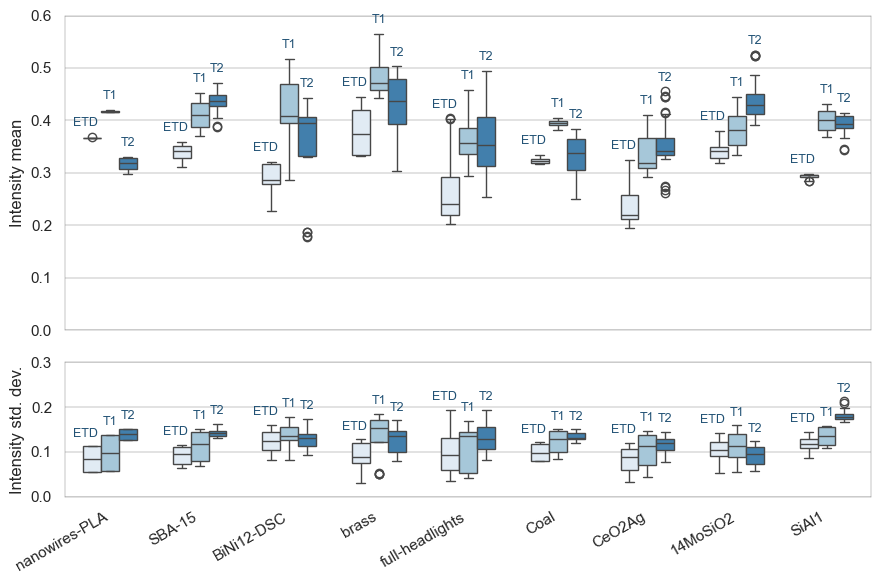

In [15]:
# intensity mean and intensity std. dev. plot
fig, (ax1, ax2) = plt.subplots(
    nrows=2, 
    ncols=1, 
    figsize=(9, 6), 
    sharex=True,
    gridspec_kw={'height_ratios': [7, 3]}
)

# top: intensity mean
sns.boxplot(
    data=df, 
    x="Specimen", 
    y="Intensity mean", 
    hue="Detector", 
    hue_order=["ETD", "T1", "T2"],
    palette=["#deebf7", "#9ecae1", "#3182bd"],
    width=0.6,
    ax=ax1
)

ax1.set_xlabel("")
ax1.set_ylabel("Intensity mean")
ax1.set_ylim(0.0, 0.6)
ax1.legend_.remove()
    
# bottom: intensity std. dev.
sns.boxplot(
    data=df, 
    x="Specimen", 
    y="Std dev", 
    hue="Detector", 
    hue_order=["ETD", "T1", "T2"],
    palette=["#deebf7", "#9ecae1", "#3182bd"],
    width=0.6,
    ax=ax2
)

ax2.set_xlabel("")
ax2.set_ylabel("Intensity std. dev.")
ax2.set_ylim(0.0, 0.3)
ax2.set_yticks([0.0, 0.1, 0.2, 0.3])
ax2.legend_.remove()
    
# shared labels
plt.setp(ax2.get_xticklabels(), rotation=30, ha="right")

x_labels = [tick.get_text() for tick in ax2.get_xticklabels()]
hue_order = ["ETD", "T1", "T2"]
offsets = [-0.2, 0, 0.2]
text_y_offset = 0.015

for i, spec in enumerate(x_labels):
    for j, det in enumerate(hue_order):
        subset = df[(df['Specimen'] == spec) & (df['Detector'] == det)]
        if not subset.empty:
            etd_label_offset = -0.07 if det == "ETD" else 0

            # top plot text
            y_pos1 = subset['Intensity mean'].max() + text_y_offset
            y_pos1 = min(y_pos1, 0.58)
            ax1.text(i + offsets[j] + etd_label_offset, y_pos1, det, ha='center', va='bottom', fontsize=9, color='#225275')
            
            # bottom plot text
            y_pos2 = subset['Std dev'].max() + text_y_offset
            y_pos2 = min(y_pos2, 0.29) 
            ax2.text(i + offsets[j] + etd_label_offset, y_pos2, det, ha='center', va='bottom', fontsize=9, color='#225275')

plt.tight_layout()
plt.savefig("dataset_plots_intensity_mean_stddev.pdf", bbox_inches="tight", pad_inches=0)
plt.show()

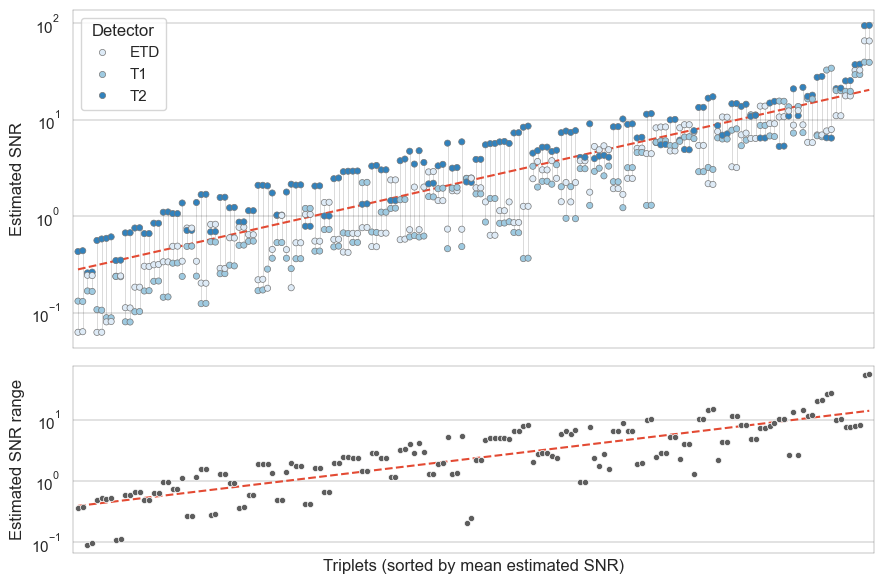

In [16]:
# SNR estimations analysis
df_snr = pd.read_csv(SNR_ESTIMATIONS_CSV)

df_snr['mean_snr'] = df_snr.groupby('triplet_ID')['SNR'].transform('mean')
df_snr = df_snr.sort_values('mean_snr')

df_snr['triplet_rank'] = df_snr.groupby('triplet_ID', sort=False).ngroup()
df_snr = df_snr[df_snr['triplet_rank'] % 1 == 0]

min_max_snr = df_snr.groupby('triplet_rank')['SNR'].agg(['min', 'max'])
min_max_snr['diff'] = min_max_snr['max'] - min_max_snr['min']

rank_means = df_snr.groupby('triplet_rank')['mean_snr'].first()

# log(y) = m*x + b
m_mean, b_mean = np.polyfit(rank_means.index.values, np.log(rank_means.values), 1)
m_diff, b_diff = np.polyfit(min_max_snr['diff'].index.values, np.log(min_max_snr['diff'].values), 1)

x_curve = np.linspace(rank_means.index.min(), rank_means.index.max(), 200)
y_curve_mean = np.exp(m_mean * x_curve + b_mean)
y_curve_diff = np.exp(m_diff * x_curve + b_diff)

fig, (ax1, ax2) = plt.subplots(
    nrows=2, 
    ncols=1, 
    figsize=(9, 6), 
    sharex=True,
    gridspec_kw={'height_ratios': [9, 5]}
)

# top plot: SNR values
ax1.vlines(
    x=min_max_snr.index, 
    ymin=min_max_snr['min'], 
    ymax=min_max_snr['max'], 
    color="#000000", 
    alpha=0.2, 
    linewidth=0.5,
    zorder=1
)
# fitted curve
ax1.plot(x_curve, y_curve_mean, color="#e34a33", linestyle="--", linewidth=1.5, zorder=3)
# values
sns.scatterplot(
    data=df_snr, 
    x='triplet_rank', 
    y='SNR', 
    hue='detector', 
    hue_order=["ETD", "T1", "T2"],
    palette=["#deebf7", "#9ecae1", "#3182bd"],
    edgecolor="#777777",
    linewidth=0.5,
    s=20,
    zorder=4,
    ax=ax1
)
ax1.set_xlabel("")
ax1.set_ylabel("Estimated SNR")
ax1.set_yscale("log", nonpositive="clip")
ax1.legend(title="Detector", loc='upper left')

# bottom plot: SNR value ranges (max - min)
# curve
ax2.plot(x_curve, y_curve_diff, color="#e34a33", linestyle="--", linewidth=1.5, zorder=1)
# ranges
sns.scatterplot(
    x=min_max_snr.index,
    y=min_max_snr['diff'],
    color="#5D5D5D",
    edgecolor="#FFFFFF",
    linewidth=0.5,
    s=20,
    zorder=2,
    ax=ax2
)
ax2.set_xlabel("Triplets (sorted by mean estimated SNR)")
ax2.set_ylabel("Estimated SNR range")
ax2.set_yscale("log", nonpositive="clip")

plt.xlim(df_snr['triplet_rank'].min() - 1, df_snr['triplet_rank'].max() + 1)
plt.xticks([]) 

plt.tight_layout()
plt.savefig("dataset_plots_snr.pdf", bbox_inches="tight", pad_inches=0)
plt.show()

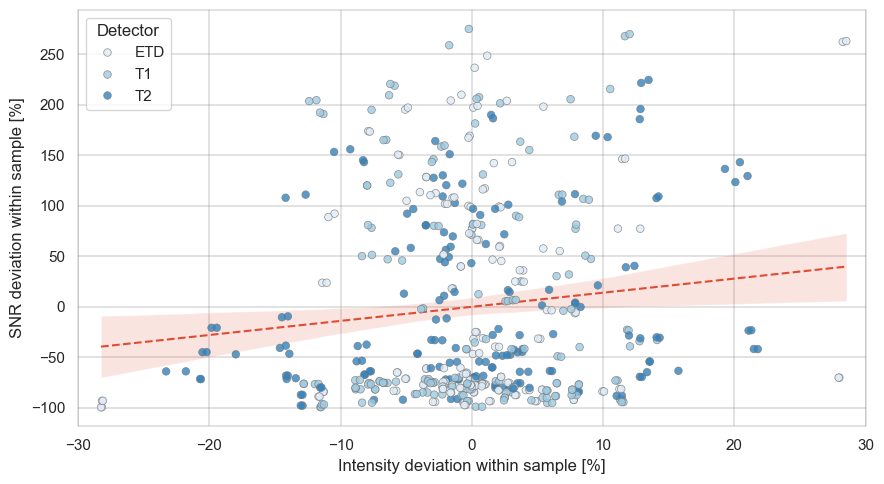

In [17]:
# within-sample mean intensity vs SNR analysis

# triplet IDs
df['merge_id'] = df['Timestamp'].dt.strftime('%Y-%m-%d_%H-%M-%S') + '-' + df['Sequence'].astype(str)

# sample IDs
df = df.sort_values(by=['Specimen', 'Timestamp'])
unique_triplets = df[['Specimen', 'Timestamp']].drop_duplicates()
unique_triplets['Sample_ID'] = unique_triplets.groupby('Specimen').cumcount() // 4
df = pd.merge(df, unique_triplets, on=['Specimen', 'Timestamp'])

# merge intensity data with SNR data
merged_df = pd.merge(df, df_snr, left_on=['merge_id', 'Detector'], right_on=['triplet_ID', 'detector'])

# percentage deviation from local sample mean
def calc_percent_dev(x):
    mean_val = x.mean()
    if mean_val == 0:
        return x * 0
    return ((x - mean_val) / mean_val) * 100
merged_df['Intensity % Dev'] = merged_df.groupby(['Specimen', 'Sample_ID', 'Detector'])['Intensity mean'].transform(calc_percent_dev)
merged_df['SNR % Dev'] = merged_df.groupby(['Specimen', 'Sample_ID', 'Detector'])['SNR'].transform(calc_percent_dev)

# Plot
plt.figure(figsize=(9, 5))

# trendline
sns.regplot(
    data=merged_df,
    x='Intensity % Dev',
    y='SNR % Dev',
    scatter=False,
    color="#e34a33",
    line_kws={"linewidth": 1.5, "linestyle": "--", "zorder": 3}
)
# data points
sns.scatterplot(
    data=merged_df,
    x='Intensity % Dev',
    y='SNR % Dev',
    hue='Detector',
    hue_order=["ETD", "T1", "T2"],
    palette=["#deebf7", "#9ecae1", "#3182bd"],
    edgecolor="#777777",
    linewidth=0.5,
    s=30,
    alpha=0.8,
    zorder=4
)

plt.xlabel("Intensity deviation within sample [%]")
plt.ylabel("SNR deviation within sample [%]")

plt.legend(title="Detector", loc='upper left')

plt.xlim(-30, 30)

plt.tight_layout()
plt.savefig("dataset_plots_intensity_vs_snr_within_sample.pdf", bbox_inches="tight", pad_inches=0)
plt.show()

In [19]:
# Null hypothesis: There is no correlation between intensity deviation and SNR deviation within samples.

# 95% certainty threshold
alpha = 0.05

spearman_corr, spearman_p = scipy.stats.spearmanr(merged_df['Intensity % Dev'], merged_df['SNR % Dev'])

print("\nSpearman correlation coeff:")
print(f"  rho     = {spearman_corr:.4f}")
print(f"  p-value = {spearman_p:.4f}")
print(f"  {'SIGNIFICANT' if spearman_p < alpha else 'NOT SIGNIFICANT'} at {1 - alpha:.0%} certainty. Null hypothesis {'REJECTED' if spearman_p < alpha else 'NOT REJECTED'}.")


Spearman correlation coeff:
  rho     = 0.0698
  p-value = 0.1174
  NOT SIGNIFICANT at 95% certainty. Null hypothesis NOT REJECTED.
